In [1]:
import matplotlib.pyplot as plt
import numpy as np
import random
import json
import math
import os

In [2]:
prod = lambda v: 1 if not v else v[-1] * prod(v[:-1])

# n_choose_k = lambda n, k: prod(range(n-k+1, n+1)) // prod(range(1, k+1))

def n_choose_k(n, k):
    ans = 1
    for i in range(1, k+1):
        ans = ans * (n+1 - i) / i
    return ans

n_arranj_k = lambda n, k: prod(range(n-k+1, n+1))

In [3]:
class ExpInfo:
    def __init__(self, name: str, json_name: str, where: str):
        self.name = name
        self.json_name =\
            os.path.join("/home/vlad/Documents/SublimeMerge/dragonfly-scripts/server_mirror/uet-htsim/htsim/sim/datacenter/dragonfly_plus_experiments/jsons/",
                         json_name)\
            if where == "fep" else\
            os.path.join("/home/vlad/Documents/SublimeMerge/dragonfly-scripts/uet-htsim/htsim/sim/datacenter/dragonfly_plus_experiments/jsons/",
                         json_name)
        self.where = where
        
    def __repr__(self):
        return f"{self.name = }, {self.json_name = }, {self.where = }"

In [4]:
ht_k_scores = {
    k: scores

    for k, scores in zip(
        [4, 6, 8],
        list(map(lambda u: list(map(str, u)) + ["default"], [
            [0, -4, -6, -8, -10],
            [0, -20, -40, -60, -80],
            [-14, -76, -138, -200, -264]
        ]))
    )
}

ht_k_mean_std_scores = {4: (-5.89, 2.1), 6: (-41.884, 5.9), 8: (-163.168, 11.7)}
ht_k_closest_to_mean = {4: -6, 6: -40, 8: -138}
ht_k_best_score = {4: 0, 6: 0, 8: -14}
ht_k_default_score = {4: -8, 6: -108, 8: -576}

In [5]:
exps = """
full_permutation, K = 4, # perms = 100, type_config_tm_pair, NSCC; full_permutation_1780957784.json; fep
full_permutation, K = 4, # perms = 100, type_config_tm_pair, RecvCC; full_permutation_1780958023.json; fep
full_permutation, K = 4, # perms = 100, type_config_tm_pair, !CC, inf QS, inf CWND; full_permutation_1780958199.json; fep
full_permutation, K = 6, # perms = 100, type_config_tm_pair, NSCC; full_permutation_1780959389.json; fep
full_permutation, K = 6, # perms = 100, type_config_tm_pair, RecvCC; full_permutation_1780961296.json; fep
full_permutation, K = 6, # perms = 100, type_config_tm_pair, !CC, inf QS, inf CWND; full_permutation_1780962530.json; fep
full_permutation, K = 8, # perms = 100, type_config_tm_pair, NSCC; full_permutation_1780968966.json; fep
full_permutation, K = 8, # perms = 100, type_config_tm_pair, RecvCC; full_permutation_1780978288.json; fep
full_permutation, K = 8, # perms = 100, type_config_tm_pair, !CC, inf QS, inf CWND; full_permutation_1780983991.json; fep
"""

# exps = """
# full_permutation, K = 4, # perms = 100, type_config_tm_pair, !CC, inf QS; full_permutation_1776859391.json; laptop
# full_permutation, K = 4, # perms = 100, type_config_tm_pair, !CC, inf QS, inf CWND; full_permutation_1777065672.json; laptop
# full_permutation, K = 4, # perms = 100, type_config_tm_pair, NSCC; full_permutation_1776862035.json; laptop
# full_permutation, K = 4, # perms = 100, type_config_tm_pair, RecvCC; full_permutation_1776867630.json; laptop
# full_permutation, K = 6, # perms = 100, type_config_tm_pair, !CC, inf QS, inf CWND; full_permutation_1779229109.json; fep
# full_permutation, K = 6, # perms = 100, type_config_tm_pair, NSCC; full_permutation_1779228538.json; fep
# full_permutation, K = 6, # perms = 100, type_config_tm_pair, RecvCC; full_permutation_1779190224.json; fep
# full_permutation, K = 8, # perms = 100, type_config_tm_pair, !CC, inf QS, inf CWND; full_permutation_1779207388.json; fep
# full_permutation, K = 8, # perms = 100, type_config_tm_pair, NSCC; full_permutation_1779230984.json; fep
# full_permutation, K = 8, # perms = 100, type_config_tm_pair, RecvCC; full_permutation_1779205304.json; fep
# """

exps = list(map(lambda x: ExpInfo(*x.split("; ")), exps.split('\n')[1:-1]))

ht_exps = {exp.name: exp.json_name for exp in exps}

In [17]:
def analyse_permutation_plot(exp_name, ax):
    with open(ht_exps[exp_name]) as fin:
        ht = json.load(fin)
    k = ht['K']
    
    scores = [str(ht_k_best_score[k]), str(ht_k_closest_to_mean[k]), "default"]
    
    if ht["HT_TYPE"] == "config_tm_pair":
        arr = [list(ht[score].values()) for score in scores]
        ax.boxplot(arr, showmeans = True)
        print([np.mean(v) for v in arr])
    else:
        arr = [ht[score]["sorted_fcts"] for score in scores]
        ax.boxplot(arr, showmeans = True)
        print([np.mean(v) for v in arr])
        
    ax.set_xticklabels(["best", "random", "default"])

In [7]:
def plot_perm_boxes(ax, k, oversub_11_lim, chernoff_dummy_oversub, set_title = True):
    for i, name in enumerate([
        f"full_permutation, K = {k}, # perms = 100, type_config_tm_pair, NSCC",
        f"full_permutation, K = {k}, # perms = 100, type_config_tm_pair, RecvCC",
        f"full_permutation, K = {k}, # perms = 100, type_config_tm_pair, !CC, inf QS, inf CWND"
    ]):
        analyse_permutation_plot(name, ax[i])
        if set_title:
            ax[i].set_title(name.split("type_config_tm_pair, ")[-1])
        ax[i].axhline(chernoff_dummy_oversub * oversub_11_lim, ls = '--', c = 'k', alpha = 0.4)
        if i == 0:
            ax[i].set_ylabel(f"K = {k}: FCT (μs)")

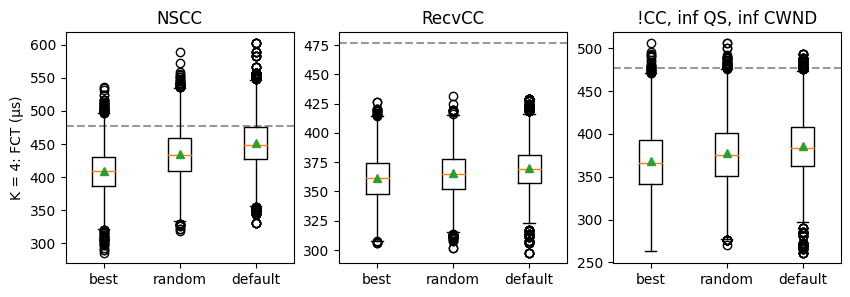

In [246]:
fig, ax = plt.subplots(1, 3, figsize = (10, 3))
plot_perm_boxes(ax, 4, 180.0, 2.65)

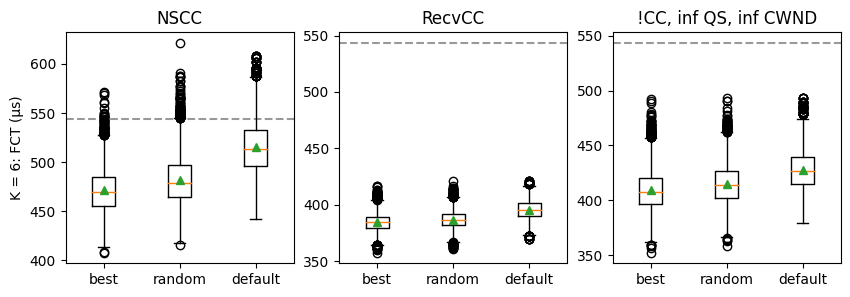

In [247]:
fig, ax = plt.subplots(1, 3, figsize = (10, 3))
plot_perm_boxes(ax, 6, 180.0, 3.02)

[494.829091, 499.2519602, 532.628918]
[387.593112, 388.78488780000004, 400.99555699999996]
[414.220609, 417.76656579999997, 431.655969]


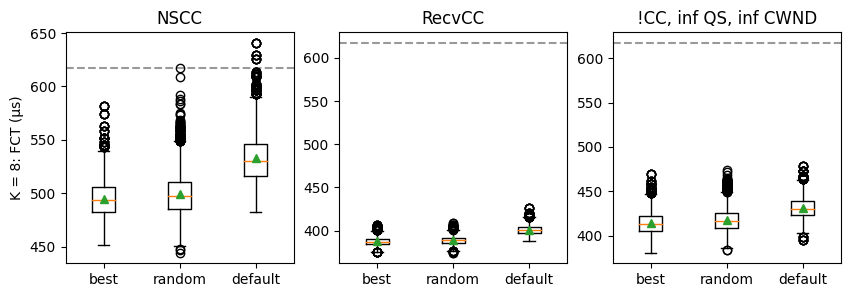

In [18]:
fig, ax = plt.subplots(1, 3, figsize = (10, 3))
plot_perm_boxes(ax, 8, 180.0, 3.43)

In [10]:
# toate (#012)[i, pe(i)] sunt sub limita de mu(1 + delta).
p_bound_sim_topo = lambda h, W, delta:\
    h**2 * (h**2 + 1) * (
        math.exp(- delta**2 / 3 * W / h**2) +
        math.exp(- delta**2 / 3 * (h-1) * W / h**2) +
        math.exp(- delta**2 / 3 * h * (h-1) * W / h**2)
    )

In [11]:
# (toate sau toate fara unul) (#012)[i, pe(i)] sunt sub limita de mu(1 + delta).
def p_bound_sim_topo_at_most_one_failure(h, W, delta):
    N = h**2 * (h**2 + 1)
    mu = W / h**2
    return N * (N-1) / 2 * (
        math.exp(- delta**2 * 2 / 3 * mu) +
        math.exp(- delta**2 * 2 / 3 * (h-1) * mu) +
        math.exp(- delta**2 * 2 / 3 * h * (h-1) * mu)
    )

In [12]:
# (cel putin N - h**2 = h**2(h**2 + 1 - 1) = h**4) (#012)[i, pe(i)] sunt sub limita de mu(1 + delta).
def p_bound_sim_topo_at_most(h, W, delta, cnt_fails):
    N = h**2 * (h**2 + 1)
    mu = W / h**2

    return n_choose_k(N, cnt_fails) * (
        math.exp(- delta**2 / 3 * cnt_fails * mu) +
        math.exp(- delta**2 / 3 * (h-1) * cnt_fails * mu) +
        math.exp(- delta**2 / 3 * h * (h-1) * cnt_fails * mu)
    )

In [42]:
print(1 - p_bound_sim_topo(h = 2, W = 481 * 2, delta = 0.325))
print(1 - p_bound_sim_topo(h = 3, W = 481 * 2, delta = 0.51))
print(1 - p_bound_sim_topo(h = 4, W = 481 * 2, delta = 0.72))
print(1 - p_bound_sim_topo(h = 5, W = 481 * 2, delta = 0.93))
print(1 - p_bound_sim_topo(h = 6, W = 481 * 2, delta = 1))

0.991592403479748
0.9914972236076803
0.9916358279954374
0.9901157395161475
0.8196706821950549


In [77]:
print(1 - p_bound_sim_topo_at_most_one_failure(h = 2, W = 481 * 2, delta = 0.257))
print(1 - p_bound_sim_topo_at_most_one_failure(h = 3, W = 481 * 2, delta = 0.43))
print(1 - p_bound_sim_topo_at_most_one_failure(h = 4, W = 481 * 2, delta = 0.615))
print(1 - p_bound_sim_topo_at_most_one_failure(h = 5, W = 481 * 2, delta = 0.813))
print(1 - p_bound_sim_topo_at_most_one_failure(h = 6, W = 481 * 2, delta = 1))

0.9904352660906232
0.9924070590195788
0.9903976271904154
0.9908755730452606
0.9837528752752793


In [171]:
print(1 - p_bound_sim_topo_at_most(h = 2, W = 481 * 2, delta = 0.208, cnt_fails = 2**2))
print(1 - p_bound_sim_topo_at_most(h = 3, W = 481 * 2, delta = 0.316, cnt_fails = 3**2))
print(1 - p_bound_sim_topo_at_most(h = 4, W = 481 * 2, delta = 0.444, cnt_fails = 4**2))
print(1 - p_bound_sim_topo_at_most(h = 5, W = 481 * 2, delta = 0.581, cnt_fails = 5**2))
print(1 - p_bound_sim_topo_at_most(h = 6, W = 481 * 2, delta = 0.723, cnt_fails = 6**2))
print(1 - p_bound_sim_topo_at_most(h = 7, W = 481 * 2, delta = 0.869, cnt_fails = 7**2))
print(1 - p_bound_sim_topo_at_most(h = 8, W = 481 * 2, delta = 1, cnt_fails = 8**2))

0.9908543094599369
0.9912373066996022
0.990378688544745
0.991698390507599
0.9919248643034609
0.9918974934191089
-1103.7079613083797


In [147]:
print(1 - p_bound_sim_topo_at_most(h = 6, W = 481 * 2, delta = 1, cnt_fails = 6**3))

1.0


In [8]:
def plot_p_bound_sim_topo(exp_name, h, W, oversub_11_lim, ax):
    with open(ht_exps[exp_name]) as fin:
        ht = json.load(fin)

    # E(experimente cu FCT sub 2(1+delta) * oversub_11_lim): 1 - p_bound_sim_topo(h, W, delta)

    best_score = '0' if h in [2, 3] else "-14"
    if ht["HT_TYPE"] == "config_tm_pair":
        fcts = np.array(list(ht[best_score].values()))
    else:
        fcts = np.array(ht[best_score]["sorted_fcts"])

    delta_mc_proba_vs_proba = [
        (delta, (fcts <= oversub_11_lim * 2 * (1 + delta)).mean(), max(0, 1 - p_bound_sim_topo(h, W, delta)))
        for delta in np.linspace(0, 1, 200)
    ]
    
    deltas = np.linspace(0, 1, 200)
    oversub_lims = 2 * (deltas + 1)
    mc_probas = np.array([(fcts <= oversub_11_lim * 2 * (1 + delta)).mean() for delta in deltas])
    probas = np.array([max(0, 1 - p_bound_sim_topo(h, W, delta)) for delta in deltas])
    
    ax.plot(oversub_lims, mc_probas, ls = "--")
    ax.plot(oversub_lims, probas, ls = "--")
    
    # stop_at = 0.75
    stop_at = 0.99
    
    ax.axvline(oversub_lims[(mc_probas >= 0.5).tolist().index(True)], c = 'k', alpha = 0.4)
    ax.axvline(oversub_lims[(mc_probas >= stop_at).tolist().index(True)], c = 'k', alpha = 0.6)
    
    # delta_potc = (math.log(math.log(h**2)) + 17) * h**2 / W
    # ax.axvline(2 * (1 + delta_potc), c = 'r', alpha = 0.4)
    
    if max(probas) >= stop_at:
        break_99 = oversub_lims[(probas >= stop_at).tolist().index(True)]
        print(f"Chernoff lim estimates {stop_at * 100}% sims finish earlier than {break_99}:1")
        ax.axvline(break_99, c = 'r', alpha = 0.6)

    # legend(["Monte-Carlo", "Chernoff\nestimate"])
    # ideal Chernoff ar fi dedesubt (sau la fel cu) Monte-Carlo

Chernoff lim estimates 99.0% sims finish earlier than 2.6532663316582914:1
Chernoff lim estimates 99.0% sims finish earlier than 2.6532663316582914:1
Chernoff lim estimates 99.0% sims finish earlier than 2.6532663316582914:1


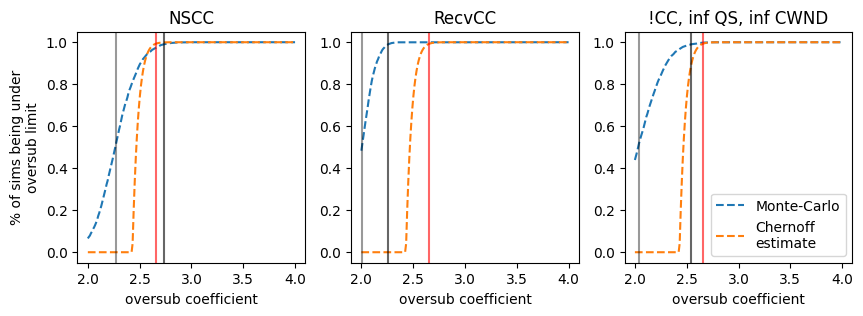

In [240]:
fig, ax = plt.subplots(1, 3, figsize = (10, 3))

h = 2

# oversub_11_lim: 54, 81, 481 * 2
for i, (oversub_11_lim, W, name) in enumerate([
    (180.5, 481 * 2, "full_permutation, K = 4, # perms = 100, type_config_tm_pair, NSCC"),
    (180.1, 481 * 2, "full_permutation, K = 4, # perms = 100, type_config_tm_pair, RecvCC"),
    (180.5, 481 * 2, "full_permutation, K = 4, # perms = 100, type_config_tm_pair, !CC, inf QS, inf CWND")
    # 10100. daca pui 2.5 x 481 se uneste perfect la 1.0 dar ayaye.
]):
    plot_p_bound_sim_topo(name, h, W, oversub_11_lim, ax[i])
    ax[i].set_title(name.split("type_config_tm_pair, ")[-1])
    
    ax[i].set_xlabel("oversub coefficient")
    if i == 0:
        ax[i].set_ylabel("% of sims being under\noversub limit")
    if i == 2:
        ax[i].legend(["Simulations", "Chernoff\nestimate"])

Chernoff lim estimates 99.0% sims finish earlier than 3.015075376884422:1
Chernoff lim estimates 99.0% sims finish earlier than 3.015075376884422:1
Chernoff lim estimates 99.0% sims finish earlier than 3.015075376884422:1


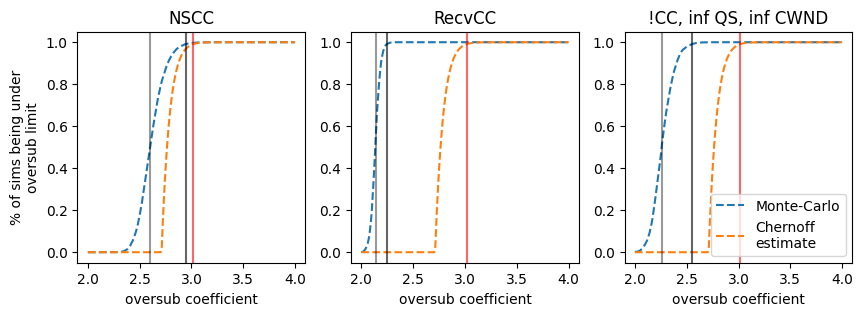

In [241]:
fig, ax = plt.subplots(1, 3, figsize = (10, 3))

h = 3

for i, (oversub_11_lim, W, name) in enumerate([
    (180.5, 481 * 2, "full_permutation, K = 6, # perms = 100, type_config_tm_pair, NSCC"),
    (180.1, 481 * 2, "full_permutation, K = 6, # perms = 100, type_config_tm_pair, RecvCC"),
    (180.5, 481 * 2, "full_permutation, K = 6, # perms = 100, type_config_tm_pair, !CC, inf QS, inf CWND")
]):
    plot_p_bound_sim_topo(name, h, W, oversub_11_lim, ax[i])
    ax[i].set_title(name.split("type_config_tm_pair, ")[-1])
    
    ax[i].set_xlabel("oversub coefficient")
    if i == 0:
        ax[i].set_ylabel("% of sims being under\noversub limit")
    if i == 2:
        ax[i].legend(["Simulations", "Chernoff\nestimate"])

Chernoff lim estimates 99.0% sims finish earlier than 3.4371859296482414:1
Chernoff lim estimates 99.0% sims finish earlier than 3.4371859296482414:1
Chernoff lim estimates 99.0% sims finish earlier than 3.4371859296482414:1


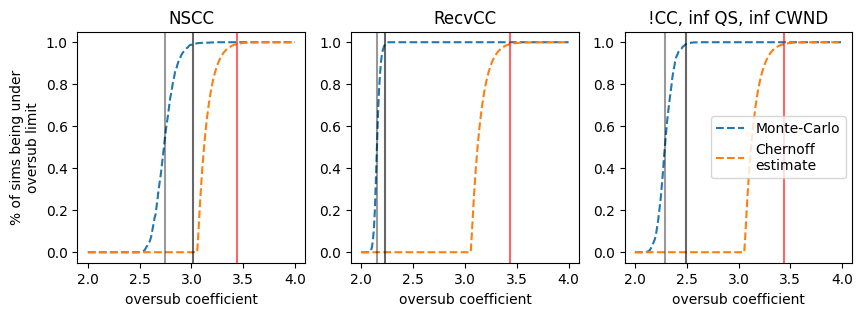

In [242]:
fig, ax = plt.subplots(1, 3, figsize = (10, 3))

h = 4

for i, (oversub_11_lim, W, name) in enumerate([
    (180.5, 481 * 2, "full_permutation, K = 8, # perms = 100, type_config_tm_pair, NSCC"),
    (180.1, 481 * 2, "full_permutation, K = 8, # perms = 100, type_config_tm_pair, RecvCC"),
    (180.5, 481 * 2, "full_permutation, K = 8, # perms = 100, type_config_tm_pair, !CC, inf QS, inf CWND")
]):
    plot_p_bound_sim_topo(name, h, W, oversub_11_lim, ax[i])
    ax[i].set_title(name.split("type_config_tm_pair, ")[-1])
    
    ax[i].set_xlabel("oversub coefficient")
    if i == 0:
        ax[i].set_ylabel("% of sims being under\noversub limit")
    if i == 2:
        ax[i].legend(["Simulations", "Chernoff\nestimate"])

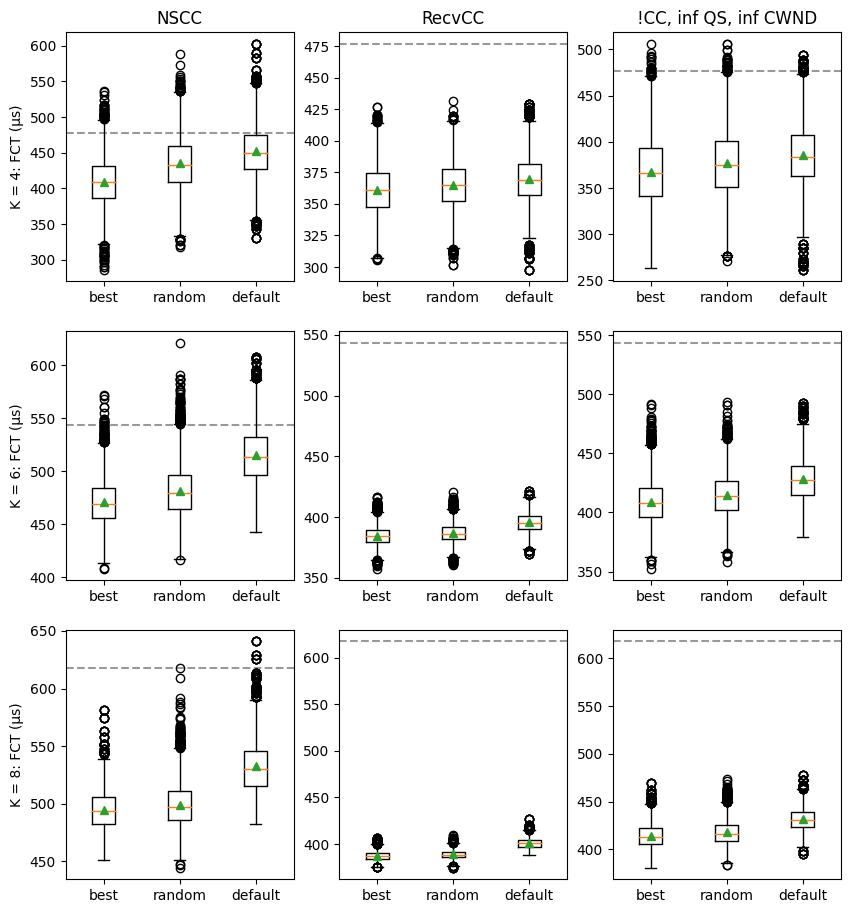

In [249]:
fig, ax = plt.subplots(3, 3, figsize = (10, 11))

plot_perm_boxes(ax[0], 4, 180.0, 2.65, set_title = True)
plot_perm_boxes(ax[1], 6, 180.0, 3.02, set_title = False)
plot_perm_boxes(ax[2], 8, 180.0, 3.43, set_title = False)

fig.savefig(
    "/home/vlad/Desktop/Probleme/LaburiDC/figs_implicit_asymmetry/oversub_high_proba_bounds_permutation_bars_100_10_5_sims_no_mean.pdf",
    bbox_inches = "tight"
)

Chernoff lim estimates 99.0% sims finish earlier than 2.6532663316582914:1
Chernoff lim estimates 99.0% sims finish earlier than 2.6532663316582914:1
Chernoff lim estimates 99.0% sims finish earlier than 2.6532663316582914:1
Chernoff lim estimates 99.0% sims finish earlier than 3.015075376884422:1
Chernoff lim estimates 99.0% sims finish earlier than 3.015075376884422:1
Chernoff lim estimates 99.0% sims finish earlier than 3.015075376884422:1
Chernoff lim estimates 99.0% sims finish earlier than 3.4371859296482414:1
Chernoff lim estimates 99.0% sims finish earlier than 3.4371859296482414:1
Chernoff lim estimates 99.0% sims finish earlier than 3.4371859296482414:1


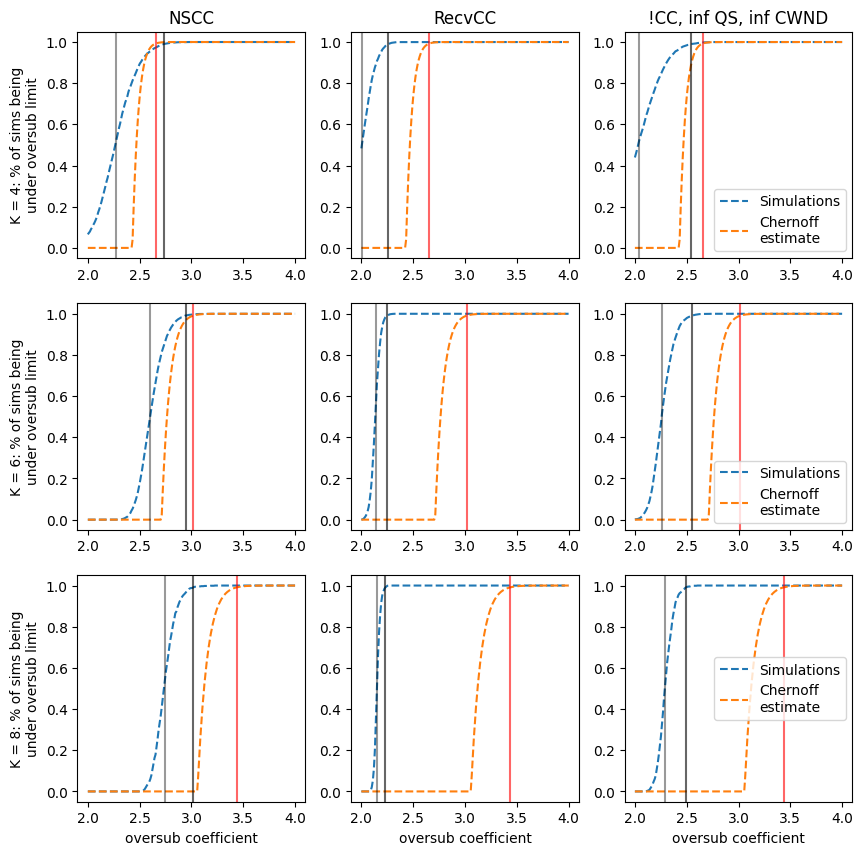

In [14]:
fig, ax = plt.subplots(3, 3, figsize = (10, 10))

for i, h in enumerate([2, 3, 4]):
    for j, (oversub_11_lim, W, name) in enumerate([
        (180.5, 481 * 2, f"full_permutation, K = {h*2}, # perms = 100, type_config_tm_pair, NSCC"),
        (180.1, 481 * 2, f"full_permutation, K = {h*2}, # perms = 100, type_config_tm_pair, RecvCC"),
        (180.5, 481 * 2, f"full_permutation, K = {h*2}, # perms = 100, type_config_tm_pair, !CC, inf QS, inf CWND")
    ]):
        # j += 3
        plot_p_bound_sim_topo(name, h, W, oversub_11_lim, ax[i, j])
        if i == 0:
            ax[i, j].set_title(name.split("type_config_tm_pair, ")[-1])
        if i == 2:
            ax[i, j].set_xlabel("oversub coefficient")

        if j == 0:
            ax[i, j].set_ylabel(f"K = {h*2}: % of sims being\nunder oversub limit")
        if j == 2:
            ax[i, j].legend(["Simulations", "Chernoff\nestimate"])

fig.savefig(
    "/home/vlad/Desktop/Probleme/LaburiDC/figs_implicit_asymmetry/oversub_high_proba_bounds_chernoff_100_10_5_sims_no_mean_v2.pdf",
    bbox_inches = "tight"
)